# Accessing Satellite Data

For the final part of this session, we are going to examine a number of different ways to in which you might choose to download satellite data, focussing on Python-based approaches. 

We will focus on Landsat data, which we have used so far. Landsat, managed by NASA and the US Geological Survey (USGS), is perhaps the most common medium-resolution multispectral optical satellite. It has a resolution of 30 m across most standard bands, a revisit time of 16 days (with the joint Landsat 8 and 9 missions providing a revisit time of 8 days), and an unmatched historical archive going back to the launch of Landsat 1 in 1971 (although early satellites were only 60 m resolution).

The alternative you might wish to consider is Sentinel-2. Sentinel-2 is the equivalent medium-resolution multispectral  offering from the European Space Agency (ESA). Sentinel-2 has some key advantages: it offers 10-metre resolution for key bands (blue, green, red, NIR), which may be of use for more precise mapping of smaller features and infrastructure. It also has a dual-satellite constellation (Sentinel-2a and -2b) which offers an enhanced revisit period of 5 days at the equator. However, it also has not been running as long, with data only going back to 2015.

Of course, both constellations also offer slightly different band combinations, some combintations of which may be of more use for specific applications:

```{figure} ../../img/landsatsentinelcomparison.png
:alt: landsat sentinel band comparison
:class: bh-primary
:width: 850px
:align: center
A comparison of bands between Sentinel-2, Landsat 8/9, and Landsat 7. (credit: [USGS/NASA](https://www.usgs.gov/centers/eros/science/usgs-eros-archive-sentinel-2-comparison-sentinel-2-and-landsat))
```

The default recommendation for this course is to work with Landsat data. It offers sufficient spatial resolution for the sort of land use change we will be assessing, as well as an impressive long-term archive and, in my opinion, is slightly easier to access and work with. However, Landsat and Sentinel-2 are both standard operational choices for a wide array of applications, so it is worth highlighting both.

## Python APIs

An Application Programming Interface (API) is a standard set of rules that allows one computer to talk to another. In our context, we are looking for efficient ways to allow our Python programmes to download data without having to manually go through graphical user interfaces, such as you have been doing earlier in this course. This is because as our datasets get larger, we don't want to be managing hundreds or thousands of images ourself!

It would be nice to have a single Python package that allows us to download our data. However, as is always the case with Python solutions, there are a number of alternative, and sometimes competing, ways of solving a problem -- and unlike up until this point, there is no clear and dominant 'winnter'. NASA offer a Python API for Earthdata through [their `earthaccess` package](https://earthaccess.readthedocs.io/en/stable/); whilst [`sentinelhub-py` offers a centralised resource](https://sentinelhub-py.readthedocs.io) for satellites in the ESA Copernicus programme (including Sentinel-2). Then there are some efforts to offer a 'one-stop shop' through [packages such as `EODAG`](https://eodag.readthedocs.io), but it's all getting a bit confusing! When everyone wants to be the one-stop-shop, all you have are a load of competing storefronts...

```{figure} https://imgs.xkcd.com/comics/standards.png
:alt: xkcd comic about competing standards
:class: bh-primary
:width: 450px
:align: center
credit: [XKCD](https://xkcd.com/927/)
```

Recently, there has been a breakthrough: rather than attempting offering a one-stop-shop, we have movde towards having a single set of _rules_ that everyone can play with. Instead of competing portals and fragmented APIs, the **SpatioTemporal Asset Catalog (STAC)** specification [establishes a universal set of rules and a common metadata structure](https://stacspec.org/en) for describing geospatial data. By standardizing how spatial footprints, timestamps, and data links are organized, everyone that provides their data as a "STAC" does so in the same way. This means that we can query multiple providers using a single set of tools without needing to learn proprietary interfaces. 

There are many STAC catalogs we could query, such as:

 - [The USGS LandsatLook STAC](https://www.usgs.gov/software/introduction-landsat-stac-tutorial) for Landsat data (requires a free NASA Earthdata / USGS EROS login to download data).
 - [The Copernicus Data Space Ecosystem (CDSE) STAC](https://documentation.dataspace.copernicus.eu/APIs/STAC.html) for ESA data (requires a free CDSE account to download data).
 - ...and [many more!](https://stacspec.org/en/about/datasets/).

Not all of these catalogues are openly available (some require logins, or require paying to download data via e.g. AWS). Also, providers can still choose to provide their own packages/tools/APIs for discovering their data (e.g. [the `landsatlook-stac` package for Landsat data](https://landstac.readthedocs.io/en/latest/)). However, the principle is: with a generic way to access STACs, you will be able to access a wide range of imagery using standard, generic toolkits.

I will teach two things in parallel today:

 - Using `pystac-client` to search STAC catalogues.
 - Using `odc` (the Open Data Cube) tool to download cloud-based satellite scenes.

We will be querying my first port of call for data: the [Microsoft Planetary Computer STAC](https://planetarycomputer.microsoft.com/docs/quickstarts/reading-stac/). This catalogue offers a [wide range of geospatial data](https://planetarycomputer.microsoft.com/CATALOG) that is free to download, without an account: all you need to do is download a small additional Python package to 'sign' requests made to the catalogue.

Using these tools you will be able to download Landsat, Sentinel-2, and much else besides.

### Using `pystac-client` to search for Landsat data

We will be using three new tools in this session that will call for new installations via `conda`: `pystac-client`, `odc-stac`, `planetary-computer`. You can install them in the usual way: by activating the correct environemnt (e.g. `conda activate gsc`) and running `conda install -c conda-forge pystac-client odc-stac planetary-computer`.

:::{note} `conda` getting sluggish?
As more packages get added to your `conda` environment, you might notice that parts of the install process are taking longer and longer! I have provided [some tips in the appendix](../../backmatter/mamba.md) that may help speed things up if you're interested.
:::

Let's import our tools.

In [246]:
import pystac_client
import planetary_computer
import odc.stac

import rioxarray as rxr
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely import box

We will first set out our particular search criteria. As mentioned on the previous page, setting out key criteria in a seperate loction at the top of the script makes it easy to rerun the script with different parameters in the future.

In [247]:
# Provide a name for our area of interest (AOI)
aoi_name = "bristol"

# Provide the bounding box coordinates for the AOI in the format [min_lon, min_lat, max_lon, max_lat]
bbox = [-2.76, 51.38,-2.43,51.53]

# Provide the date range for the search in the format "YYYY-MM-DD/YYYY-MM-DD"
daterange = "2026-06-01/2026-08-31"  # summer 2026

# Provide a cloud cover percentage threshold for filtering the search results
max_cloud_percent = 20  # maximum cloud cover percentage

# Provide a 'collection' from the Microsoft Planetary Computer STAC API to search for imagery. 
# For example, "landsat-c2-l2" for Landsat Collection 2 Level 2 data.
# See https://planetarycomputer.microsoft.com/CATALOG for more examples
collection = "landsat-c2-l2"

We can turn the bbox list into a `GeoPandas` dataframe as well:

In [195]:
aoi = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

aoi.explore()

Next, we willl connect to the Microsoft Planetary Computer (MPC) by providing the MPC STAC address using the `pystac_client`. We will need to URL link to the dynamic STAC, which will be available on various documentation. 

Data can be downloaded ‘anonymously’ (i.e. without registration), but download speeds may be throttled unless you can properly "sign" your requests. This is made easy for us through a very small additional package, unique to the MPC STAC, called `planetary_computer`.

In [248]:
# Connect to the MPC
stac_url = "https://planetarycomputer.microsoft.com/api/stac/v1"

catalog = pystac_client.Client.open(
    stac_url,
    modifier=planetary_computer.sign_inplace,  # only needed for MPC

    )

`catalog` can be viewed, showing we have succesfully connected to the MPC.

In [249]:
catalog

<Client id=microsoft-pc>

It’s challenging to understand what’s going on with this returned object, but at least we know we’ve succesfully connected.

Now, we can search individual collections. We can loop through all the collections avialable to us (there's a lot, so I'll stop printing after 10 collections):

In [ ]:
# print the first 10 collections in the catalog
for i, col in enumerate(catalog.get_collections()):
    if i >= 10:
        break
    print(col.id, col.title)

3dep-lidar-classification USGS 3DEP Lidar Classification
3dep-lidar-copc USGS 3DEP Lidar Point Cloud
3dep-lidar-dsm USGS 3DEP Lidar Digital Surface Model
3dep-lidar-dtm USGS 3DEP Lidar Digital Terrain Model
3dep-lidar-dtm-native USGS 3DEP Lidar Digital Terrain Model (Native)
3dep-lidar-hag USGS 3DEP Lidar Height above Ground
3dep-lidar-intensity USGS 3DEP Lidar Intensity
3dep-lidar-pointsourceid USGS 3DEP Lidar Point Source
3dep-lidar-returns USGS 3DEP Lidar Returns
3dep-seamless USGS 3DEP Seamless DEMs


This is fine for validating the collections of small STAC catalogs, but for the Microsoft Planetary Computer it's easier to [explore all the collections in the online data catalogue](https://planetarycomputer.microsoft.com/CATALOG). Individual collection pages will show us more data. For instance, [at the Landsat Collection-2 Level-2 site](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2), we can see that the collection name is landsat-c2-l2, as well as the various “assets” contained within the dataset, such as all the bands and metadata.

The only function you really need to understand is the `search()` function, which is the standardised search tool.

There are always some consistent things you can search a STAC catalogue for, including `time_range` and some sort of spatial search - which could be `bbox` in the form of `[xmin, ymin, xmax, ymax]`, or using the `intersects` parameter by feeding a GeoJSON or shapely geometry feature. All **will work in lat/lon only**, as this is how STACs are spatially indexed.

Below, I have constructed a search query for the catalogue: I have provided the collection we wish to search, the bounding box, the date range, and additional collection-specific queries as a dictionary (namely, the cloud cover parameter, which is stored under the attribute name `eo:cloud_cover`). 

Additionally, as we are looking for a single 'best' image, I have used the `sortby` argument to tell the `search` function to return our data from the least to most cloudy.

In [252]:
# Search for cloud-free Landsat imagery in Summer
search = catalog.search(
    collections=[collection],
    bbox=bbox,
    datetime=daterange,
    query={
        "eo:cloud_cover": {"lt": max_cloud_percent},  # Cloud cover less than 15%
        }, 
    sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}]
)

# Convert the search result object into a list of `pystac.Item` objects
items = search.item_collection()
print(f"Found {len(items)} matching scene(s).")

Found 6 matching scene(s).


6 valid items have been returned in the form of a `pystac` `ItemCollection`. Let’s take a look at what the first `Item` looks like (this should be our least cloudy item).

In [253]:
item = items[0]
item

<Item id=LC09_L2SP_203024_20260711_02_T1>

Each `item` will have its own set of properties.

In [204]:
item.properties

{'gsd': 30,
 'created': '2026-07-13T15:36:27.448769Z',
 'sci:doi': '10.5066/P9OGBGM6',
 'datetime': '2026-07-11T11:04:17.508127Z',
 'platform': 'landsat-9',
 'proj:shape': [7991, 7911],
 'description': 'Landsat Collection 2 Level-2',
 'instruments': ['oli', 'tirs'],
 'eo:cloud_cover': 0.01,
 'proj:transform': [30.0, 0.0, 407385.0, 0.0, -30.0, 5846415.0],
 'view:off_nadir': 0,
 'landsat:wrs_row': '024',
 'landsat:scene_id': 'LC92030242026192LGN00',
 'landsat:wrs_path': '203',
 'landsat:wrs_type': '2',
 'view:sun_azimuth': 148.13480369,
 'landsat:correction': 'L2SP',
 'view:sun_elevation': 57.28280422,
 'landsat:cloud_cover_land': 0.01,
 'landsat:collection_number': '02',
 'landsat:collection_category': 'T1',
 'proj:code': 'EPSG:32630'}

These additional variables are what we can use to build the `query` dictionary (note the presence of `eo:cloud_cover`). Some are specific to each dataset (for instance, sentinel-2 has things like `s2:high_proba_clouds_percentage` and `s2:mean_solar_zenith`) so it’s always worth checking what you can search for.

We can also see what data is available to us: in STAC terms, these are called `assets`.

In [211]:
# print out item asset names
assets = list(item.assets.keys())

assets

['qa',
 'ang',
 'red',
 'blue',
 'drad',
 'emis',
 'emsd',
 'trad',
 'urad',
 'atran',
 'cdist',
 'green',
 'nir08',
 'lwir11',
 'swir16',
 'swir22',
 'coastal',
 'mtl.txt',
 'mtl.xml',
 'mtl.json',
 'qa_pixel',
 'qa_radsat',
 'qa_aerosol',
 'tilejson',
 'rendered_preview']

(Again, this is available on the [dataset information](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2)). Hopefully some of these names will look familiar!

### Downloading data with `odc-stac`

Let's commit to a scene and download it. Below, I select the first item (as discussed, this should be the least cloudy), but if you find it isn't appropriate, you can try and different index (e.g. `items[1]`).

I also extract some useful metadata as strings from the `item.properties`: this will come is useful when we come to save our image.

In [254]:
item = items[0]

date = item.properties['datetime'][:10]
epsg = item.properties['proj:code']
satellite = item.properties['platform']

print(f"Selected Scene ID: {item.id}")
print(f"Acquisition Date: {item.properties['datetime']}")
print(f"Cloud Cover: {item.properties['eo:cloud_cover']}%")
print(f"Projection: {item.properties['proj:code']}")

Selected Scene ID: LC09_L2SP_203024_20260711_02_T1
Acquisition Date: 2026-07-11T11:04:17.508127Z
Cloud Cover: 0.01%
Projection: EPSG:32630


Now, we can use `odc.stac.load()` to load our data. By default, the data will be downloaded in the native CRS (the appropriate UTM zone), but in the commented-out arguments below you could see how you request something different.

In [237]:
# Requested bands - I've commented out some we don't need for now, but you can uncomment them if you want to use them later
bands = [
    # 'coastal',  # band 1, coastal/aerosol
    'blue',  # band 2, blue
    'green',  # band 3, green
    'red',  # band 4, red
    'nir08',  # band 5, near-infrared
    # 'swir16',  # band 6, shortwave infrared 1
    # 'swir22',  # band 7, shortwave infrared 2
]

# Load requested bands directly into an xarray.Dataset using odc-stac
ds = odc.stac.load(
    [item],
    bands=bands,
    bbox=bbox,
    # crs="EPSG:XXXX",  # Not used for now: by default, will use the native projection of the imagery
    # resolution=30, # Not used for now: by default, will use the native resolution of the imagery
).squeeze()

# xarray is 'lazy' by default, meaning it doesn't load the data into memory until you explicitly ask for it.
# The `.compute()` method forces the data to be loaded into memory, which can take some time depending on the size of the dataset.
ds.compute()

ds

<xarray.Dataset> Size: 3MB
Dimensions:      (y: 561, x: 768)
Coordinates:
  * y            (y) float64 4kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 6kB 5.167e+05 5.167e+05 ... 5.396e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-07-11T11:04:17.508127
Data variables:
    blue         (y, x) uint16 862kB 9134 9134 9129 9131 ... 9197 9200 9117 9335
    green        (y, x) uint16 862kB 10435 10461 10457 ... 10483 10168 10865
    red          (y, x) uint16 862kB 11119 11116 11132 ... 11154 10568 11699
    nir08        (y, x) uint16 862kB 9591 9592 9597 9616 ... 20110 19456 21249

Great - we have it! `odc-stac` defaults to a different set - rather than having a `band` dimension, each band is given its own named data variable.

This is because the `odc.stac.load()` function actually accepts a `list` of items, not just an `item`. If I had provided more than one, I would have received a dimension `time` - i.e., our raster dataset has become a datacube! In this format, individual band variables make more sense. However, for now, we can turn ourselves back into a `band` dimension using:

In [238]:
# stack variables into a band dimension
ds = ds.to_array(dim="band").squeeze()

# add the band names as a long_name attribute to the dataset
ds.attrs["long_name"] = list(ds["band"].values)

ds

<xarray.DataArray (band: 4, y: 561, x: 768)> Size: 3MB
array([[[ 9134,  9134,  9129, ...,  8858,  9597,  9363],
        [ 9155,  9135,  9131, ...,  8965,  9334,  9164],
        [ 9169,  9137,  9135, ...,  9001,  9238,  9355],
        ...,
        [ 8659,  8851,  8597, ...,  9111,  9011,  9182],
        [ 8615,  8799,  8750, ...,  9168,  9010,  9278],
        [ 8586,  8739,  8791, ...,  9200,  9117,  9335]],

       [[10435, 10461, 10457, ...,  9823, 10524, 10368],
        [10455, 10465, 10471, ...,  9953, 10366, 10172],
        [10485, 10460, 10485, ...,  9737, 10027, 10084],
        ...,
        [ 9653,  9973,  9538, ..., 10280, 10226, 10451],
        [ 9634,  9853,  9790, ..., 10413, 10205, 10653],
        [ 9560,  9768,  9904, ..., 10483, 10168, 10865]],

       [[11119, 11116, 11132, ...,  9865, 10980, 10694],
        [11154, 11152, 11163, ..., 10362, 10797, 10555],
        [11192, 11136, 11178, ...,  9856, 10321, 10431],
        ...,
        [ 9904, 10531,  9563, ..., 10800, 10655, 11021],
        [ 9815, 10305, 10244, ..., 11040, 10589, 11402],
        [ 9741, 10121, 10392, ..., 11154, 10568, 11699]],

       [[ 9591,  9592,  9597, ..., 15836, 14803, 14930],
        [ 9672,  9655,  9664, ..., 16434, 15789, 15750],
        [ 9787,  9744,  9746, ..., 16336, 15820, 14342],
        ...,
        [16860, 16871, 19281, ..., 19648, 19616, 20278],
        [16863, 16595, 17422, ..., 19847, 19558, 20680],
        [16593, 16775, 17466, ..., 20110, 19456, 21249]]],
      shape=(4, 561, 768), dtype=uint16)
Coordinates:
  * band         (band) object 32B 'blue' 'green' 'red' 'nir08'
  * y            (y) float64 4kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 6kB 5.167e+05 5.167e+05 ... 5.396e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-07-11T11:04:17.508127
Attributes:
    long_name:  ['blue', 'green', 'red', 'nir08']

We still need to do the usual conversion to fix our NaN values and convert to surface reflectance:

In [223]:
# set zero to NaN
ds = ds.where(ds > 0)

# Surface reflectance scaling values
ds = ds * 0.0000275 - 0.2  # convert to SR

But after this, we have our working array!

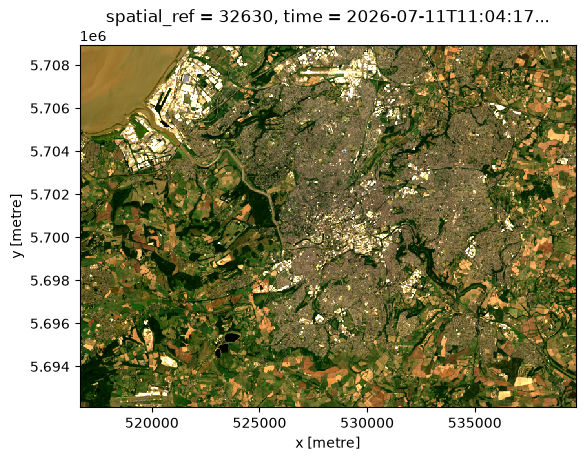

In [224]:
rgb = ds.sel(band=["red", "green", "blue"])

fig, ax = plt.subplots()
rgb.plot.imshow(ax=ax, robust=True)
ax.set_aspect("equal")

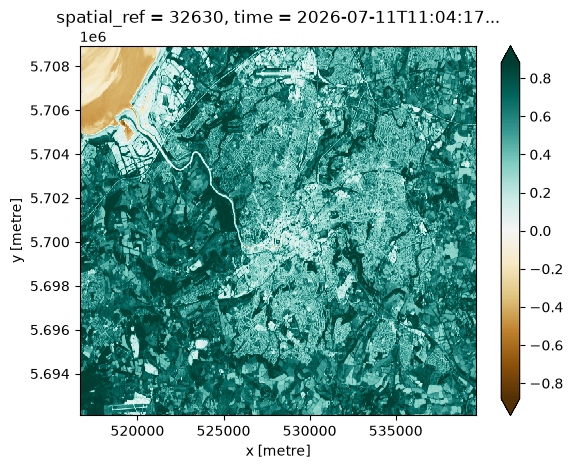

In [232]:
# Calculate NDVI
ndvi = (ds.sel(band="nir08") - ds.sel(band="red")) / (ds.sel(band="nir08") + ds.sel(band="red"))

ndvi.plot.imshow(cmap="BrBG", robust=True)


By taking advantage the parameters we saved earlier, we can save this under a sensible name:

In [239]:
filename = f"{aoi_name}_{date}_{satellite}.tif"

print('Saving to:', filename)

ds.rio.to_raster(filename, driver="GTiff", compress="deflate")

Saving to: bristol_2026-07-11_landsat-9.tif


And load it again!

In [245]:
ds_loaded = rxr.open_rasterio(filename, masked=True).squeeze()

ds_loaded['band'] = list(ds_loaded.attrs["long_name"])

ds_loaded

<xarray.DataArray (band: 4, y: 561, x: 768)> Size: 7MB
[1723392 values with dtype=float32]
Coordinates:
  * band         (band) <U5 80B 'blue' 'green' 'red' 'nir08'
  * y            (y) float64 4kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 6kB 5.167e+05 5.167e+05 ... 5.396e+05 5.397e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      ('blue', 'green', 'red', 'nir08')

### Get other datasets

In the interests of not repeating these long instructions over multiple datasets, I have [provided a "Recipes" section within this course content](../../recipes/index.md). These recipes aim to provide stripped-down notebooks that you can edit, copy, and adapt to your liking. Extraneous explanation is removed to make it easier to parse for code than these pages!

Three recipes are provided for this session, showing you how you can download Landsat, Sentinel-2, and Copernicus DEM data. 

 - [Download Landsat data](../../recipes/download-landsat.ipynb)
 - [Download Sentinel-2 data](../../recipes/download-sentinel-2.ipynb)
 - [Download Copernicus DEM-30 data](../../recipes/download-copdem.ipynb)

You might notice that the Landsat and Copernicus DEM recipes produce the data for the Week 4 course. This is the principle of reproducable and open code - code that allows people to reproduce what is presented elsewhere, inspect it for faults and errors, and contribute to and improve upon it.

## Optional: Online GUI Sites

:::{note}
The online GUI sites are provided as an alternative fallback option for those who might not be able to get the Python API approaches working: however, for the purposes of today's session, don't spend any time trying out the online GUIs. If done correctly, it should be quicker to use with the Python APIs above to experiment with finding and using data.
:::

### Landsat Data: USGS EarthExplorer

This original dataset from the first notebook of this session was downloaded from [the USGS EarthExplorer data browser](https://earthexplorer.usgs.gov/). Once you have registered for an account, this resource is the best online source for free download of Landsat data (and a multitude of other datasets).

As you have seen, this resource has the downside of downloading entire tiles of Landsat imagery rather than clipped regions of interest, and also keeps them as seperate GeoTIFFs. However, it is easy to search for and find data. If you prefer to use a web-based graphical user interface for Landsat data, you are more than welcome to use the USGS EarthExplorer for this course. 

The search functionality is pretty self-explanatory, allowing you to search for a given geographic region, filter by date and cloud cover, and search specific datasets (for our purposes, the **Landsat Collection 2 Level-2 data will be our go-to option**). [A very useful video tutorial is available at this link](https://www.usgs.gov/media/videos/how-use-usgs-earthexplorer-download-imagery); an [an official written guide is available here](https://www.usgs.gov/media/files/earthexplorer-user-interface-help-document); and [a slightly more user-friendly guide is available here](https://www.mapping101.com/skills/usgs-landsat).

### Sentinel-2 Data: Copernicus Data Space Ecosystem (CDSE)

You can use [the Copernicus Data Space Ecosystem Browser](https://browser.dataspace.copernicus.eu/) to search for Sentinel-2 imagery in a browser. You will need to create and sign in with an account to download data. [A short video guide is available here](https://www.youtube.com/watch?v=vgjXk85LIbE).

The interface isn't quite as easy to use as the USGS EarthExplorer (in my opinion), but offers much the same content: you can create a polygon to search by area, search a single or range of dates, and filter by properties such as cloud cover. It even has a neat function where you can do some simple visualisations such as false colour and NDVI. 

You have access to multiple collections: **use the Sentinel-2 L2A data** over the L1A data (L2A data is atmospherically corrected surface reflectance).

To convert from Sentinel-2 digital numbers to surface reflectance, divide by 10,000.

## Summary

We have seen how we can access satellite data (with a focus on Landsat multispectral imagery), acknowledging that there are many ways we can do this and the 'correct' method is the one that works for you! STAC catalogues are an increasingly common workflow the geospatial industry is centralising around, and we can use `pystac_client` and `odc-stac` to download our data, using the Microsoft Planetary Computer as an excellent freely available example. If all else fails, we know how to use web browsers to download Landsat and Sentinel-2 data from official sources.